Since we completed 1CCCV charge protocol now let's charge with 1CPCV.
First, we need to define what is the value of 1P.
1P = Vnominal * 1C
I could not find any Vonimal parameter in the Chen2020. So I will take Vnominal as 3.6V this specific cell.

In [100]:
import pybamm
import matplotlib.pyplot as plt

In [101]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%

{'Ambient temperature [K]': 298.15,
 'Bulk solvent concentration [mol.m-3]': 2636.0,
 'Cation transference number': 0.2594,
 'Cell cooling surface area [m2]': 0.00531,
 'Cell thermal expansion coefficient [m.K-1]': 1.1e-06,
 'Cell volume [m3]': 2.42e-05,
 'Contact resistance [Ohm]': 0,
 'Current function [A]': 5.0,
 'EC diffusivity [m2.s-1]': 2e-18,
 'EC initial concentration in electrolyte [mol.m-3]': 4541.0,
 'Electrode height [m]': 0.065,
 'Electrode width [m]': 1.58,
 'Electrolyte conductivity [S.m-1]': <function electrolyte_conductivity_Nyman2008 at 0x0000024D396E89D0>,
 'Electrolyte diffusivity [m2.s-1]': <function electrolyte_diffusivity_Nyman2008 at 0x0000024D396E8940>,
 'Initial SEI thickness [m]': 5e-09,
 'Initial concentration in electrolyte [mol.m-3]': 1000.0,
 'Initial concentration in negative electrode [mol.m-3]': np.float64(872.9150690373064),
 'Initial concentration in positive electrode [mol.m-3]': np.float64(53889.21786785448),
 'Initial temperature [K]': 298.15,
 'L

In [102]:
Vnom = 3.6 # Nominal voltage of the cell
Qnom = parameter_values["Nominal cell capacity [A.h]"]
P_1P = Vnom * Qnom # Nominal power of the cell
print("Nominal power of the cell: ", P_1P, "W")

Nominal power of the cell:  18.0 W


In [103]:
CPCV_Charging = pybamm.Experiment([
    f"Charge at {P_1P} W until 4.2 V",
     "Hold at 4.2 V until C/20"])


In [104]:
model = pybamm.lithium_ion.DFN() # Create a DFN model
sim = pybamm.Simulation(model, experiment=CPCV_Charging,parameter_values=parameter_values)
sim.solve() # Solve the simulation

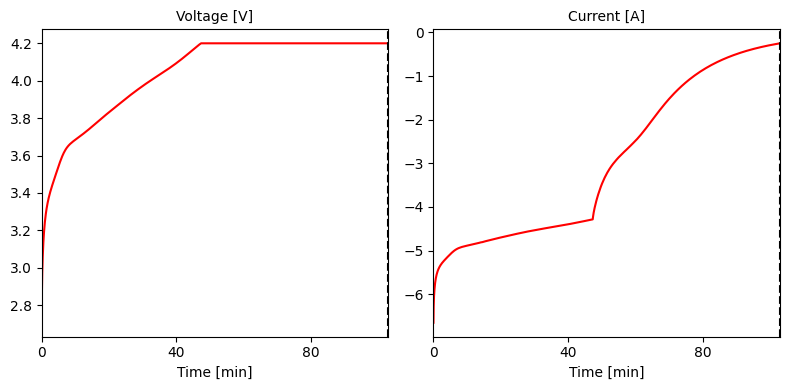

In [105]:
sim.solution.cycles
qp = pybamm.QuickPlot(sim.solution,output_variables=["Voltage [V]", "Current [A]",], time_unit="minutes")
qp.plot(qp.max_t) # Plot the voltage and current over time for the entire experiment

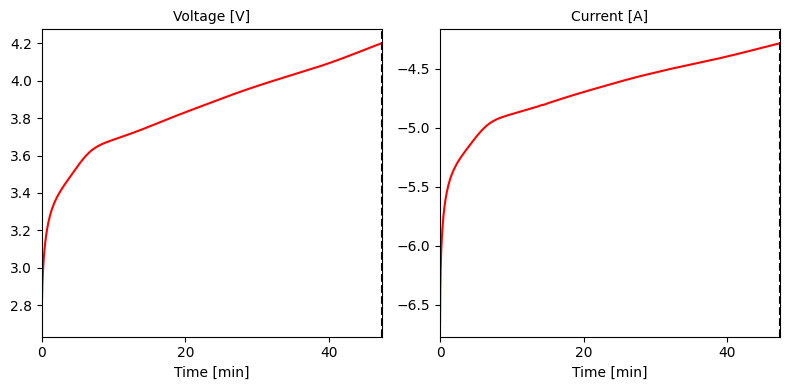

In [106]:
CP_Phase = sim.solution.cycles[0] # Get the constant power phase of the charging cycle with 18W
qp_CP = pybamm.QuickPlot(CP_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CP.plot(qp_CP.max_t) # Plot the voltage and current over time for the constant power

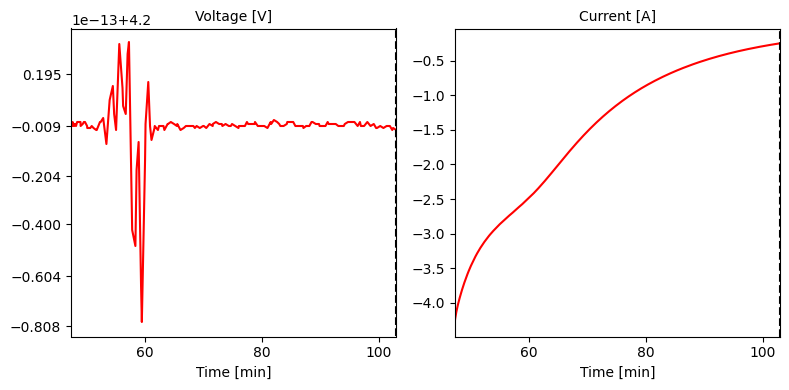

In [107]:
CV_Phase = sim.solution.cycles[1] # Get the constant voltage phase of the charging cycle with 4.2V
qp_CV = pybamm.QuickPlot(CV_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CV.plot(qp_CV.max_t) # Plot the voltage and current over time for the constant voltage with 4.2V